# Day 9 · Image matching (descriptors, FLANN, Lowe's ratio test) + mini project: logo detector

**Course lab:** `CV-Week2-Lecture2.ipynb` (Day 9)
**Notes chapter:** `week-2/notes/02_image_matching_flann_logo_detector.md`
**Builds on:** Day 8 (`day08_feature_detection_panorama.ipynb`): keypoints, SIFT, ORB, homography, RANSAC.

**What you will learn**
1. What a descriptor is, how two descriptors are compared (L2 vs Hamming distance) and how matches are found (brute force vs **FLANN**).
2. **Lowe's ratio test**: why `m.distance < 0.7 * n.distance` throws away most wrong matches.
3. The course code with a real logo/scene pair, every parameter explained, and a crash in the course code that appears with small images (and how to guard against it).
4. Measured experiments: ratio threshold sweep, ORB vs SIFT, brute force vs FLANN speed, what happens when the logo is **not** in the scene.
5. Mini project: a **logo detector** that draws a box around the logo, tested with known ground truth (rotation, zoom, perspective) and on scenes that do *not* contain the logo.

**Run time:** about 15–30 seconds on a laptop CPU. All numbers in the text come from the outputs below.

## 1 · Theory recap in plain language

**Matching = finding the same physical point in two images.** Day 8 gave us keypoints (*where*) and descriptors (*what it looks like*). Matching compares descriptors: two keypoints "match" if their descriptors are close.

**How close? It depends on the descriptor type:**

| Descriptor | Type | Size | Distance | OpenCV norm |
|---|---|---|---|---|
| SIFT | 128 floats | 512 bytes | Euclidean (L2): √Σ(aᵢ−bᵢ)² | `cv2.NORM_L2` |
| ORB / BRIEF | 256 bits | 32 bytes | **Hamming**: number of bits that differ (XOR + count) | `cv2.NORM_HAMMING` |

**Finding the nearest descriptor:**
- **Brute force (`BFMatcher`)**: compare every descriptor in image A with every descriptor in image B. Exact, simple, cost grows as N×M.
- **FLANN** (*Fast Library for Approximate Nearest Neighbours*): first builds an **index** (a search structure), then answers queries quickly but **approximately** (it may occasionally miss the true nearest neighbour). Like looking a word up in a dictionary by its first letters rather than reading every page.
  - for float descriptors (SIFT): **KD-trees** (`algorithm=1`): repeatedly split the 128-D space in half along one dimension; several randomised trees are searched in parallel.
  - for binary descriptors (ORB): **LSH**, *Locality Sensitive Hashing* (`algorithm=6`): hash random subsets of bits into buckets, so similar bit strings land in the same bucket; only that bucket is searched.

**Lowe's ratio test (SIFT paper, 2004).** For each descriptor, find its **2** nearest neighbours m (best) and n (second best). Keep the match only if `m.distance < 0.7 × n.distance`.
*Analogy:* you're looking for your friend in a crowd. If one face looks clearly more like them than any other face, it's probably them. If two faces look almost equally similar, you can't be sure, so you don't wave at either. Repetitive patterns (windows, bricks, text) produce exactly these ambiguous "two similar candidates" cases.

**Homography + RANSAC (from Day 8):** a flat logo seen from any viewpoint is related to its image in the scene by a 3×3 homography H. With ≥ 4 good matches, RANSAC finds the H that most matches agree with, ignoring wrong matches (outliers). Projecting the logo's 4 corners with H gives the box to draw.

## 2 · Setup and data

The course code loads `left.jpg` and `right.jpg` (two photos of books, *not* a logo and a scene), and the exercise text mentions `logo.jpg` and `scene.jpg`; **none of these files were provided**. We use the classic OpenCV pair made for exactly this task: `box.png` (a cereal box, our "logo") and `box_in_scene.png` (the box in a cluttered scene, rotated and partly hidden). We also use the OpenCV logo and several images that do **not** contain the box.

OpenCV version: 5.0.0


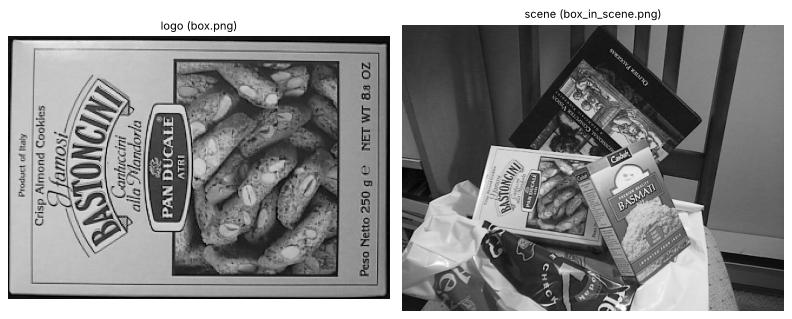

In [1]:
%matplotlib inline
%config InlineBackend.figure_formats = ["jpeg"]
import time
import numpy as np
import matplotlib.pyplot as plt
import cv2

plt.rcParams["figure.dpi"] = 80
print("OpenCV version:", cv2.__version__)

import os, urllib.request

DATA, OUT = "data", "output"            # data/ and output/ sit next to this notebook (both are git-ignored)
os.makedirs(DATA, exist_ok=True)
os.makedirs(OUT, exist_ok=True)

OPENCV_SAMPLES = "https://raw.githubusercontent.com/opencv/opencv/4.x/samples/data/"
OPENCV_STITCH  = "https://raw.githubusercontent.com/opencv/opencv_extra/4.x/testdata/stitching/"

def download(url, path):
    """Download url to path once; later runs reuse the cached file."""
    if os.path.exists(path) and os.path.getsize(path) > 0:
        return path
    print("downloading", url)
    tmp = path + ".part"
    try:
        urllib.request.urlretrieve(url, tmp)
        os.replace(tmp, path)
    except Exception as e:
        raise RuntimeError(
            f"Could not download {url}\n({e})\n"
            f"Are you offline? Open the URL in a browser, save the file as\n  {os.path.abspath(path)}\n"
            "and re-run this cell. (Or use any image/video of your own and change the file name.)") from e
    return path

def to_rgb(img):
    """OpenCV stores colour as B,G,R; matplotlib expects R,G,B. Grey images are left alone."""
    return img if img.ndim == 2 else cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

def show(images, titles=None, cols=None, size=4.5, max_side=900):
    """Show one or more OpenCV images side by side (downscaled for a small notebook file)."""
    if not isinstance(images, (list, tuple)):
        images, titles = [images], [titles]
    cols = cols or len(images)
    rows = (len(images) + cols - 1) // cols
    aspect = max(im.shape[0] / im.shape[1] for im in images)          # height/width of the tallest image
    fig, axes = plt.subplots(rows, cols, figsize=(size * cols, size * rows * aspect + 0.35 * rows), squeeze=False)
    for ax in axes.ravel():
        ax.axis("off")
    for i, img in enumerate(images):
        s = min(1.0, max_side / max(img.shape[:2]))
        if s < 1:
            img = cv2.resize(img, None, fx=s, fy=s, interpolation=cv2.INTER_AREA)
        ax = axes.ravel()[i]
        ax.imshow(to_rgb(img), cmap="gray" if img.ndim == 2 else None)
        if titles and titles[i]:
            ax.set_title(titles[i], fontsize=10)
    plt.tight_layout()
    plt.show()

for name in ["box.png", "box_in_scene.png", "opencv-logo.png", "messi5.jpg", "building.jpg",
             "home.jpg", "left01.jpg", "graf1.png", "graf3.png"]:
    download(OPENCV_SAMPLES + name, os.path.join(DATA, name))

def imread_checked(path, flags=cv2.IMREAD_COLOR):
    img = cv2.imread(path, flags)
    if img is None:
        raise FileNotFoundError(f"cv2.imread could not read {path}")
    return img

show([imread_checked(os.path.join(DATA, "box.png")), imread_checked(os.path.join(DATA, "box_in_scene.png"))],
     ["logo (box.png)", "scene (box_in_scene.png)"], size=5)

## 3 · The course code: ORB + FLANN (LSH) + ratio test

Same calls, same parameters and the same variable names as the course; only the file names changed, and the display line is corrected (see the comment).

keypoints: logo 453, scene 500 | knn pairs 453 | good after ratio test: 20
drawMatches output: (384, 836, 3) -> a 3-channel BGR image, even though the inputs were grey


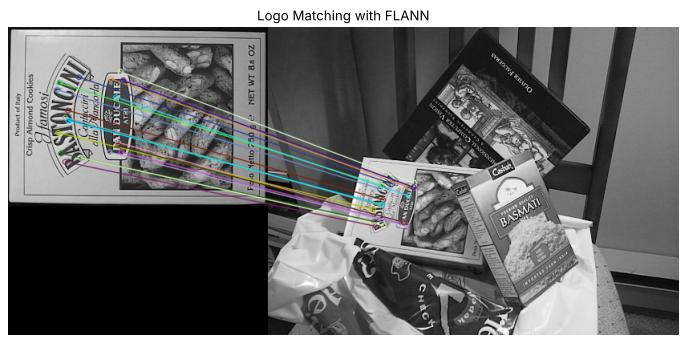

In [2]:
# Load two images (logo and scene) in greyscale: descriptors are computed on brightness only
logo = cv2.imread(os.path.join(DATA, 'box.png'), cv2.IMREAD_GRAYSCALE)            # course: 'left.jpg'
scene = cv2.imread(os.path.join(DATA, 'box_in_scene.png'), cv2.IMREAD_GRAYSCALE)  # course: 'right.jpg'

# Initialize ORB detector (default nfeatures=500)
orb = cv2.ORB_create()
kp1, des1 = orb.detectAndCompute(logo, None)     # kp1: keypoints of the logo, des1: (N1, 32) uint8
kp2, des2 = orb.detectAndCompute(scene, None)    # kp2/des2: same for the scene

# FLANN parameters for ORB (using LSH index, because ORB descriptors are binary)
FLANN_INDEX_LSH = 6
index_params = dict(algorithm=FLANN_INDEX_LSH,
                   table_number=6,       # number of hash tables (more = more accurate, more memory)
                   key_size=12,          # bits per hash key (longer = smaller, purer buckets)
                   multi_probe_level=1)  # also search neighbouring buckets (0 = only the exact bucket)
search_params = dict(checks=50)          # how many candidates/leaves to examine per query (accuracy vs speed)

flann = cv2.FlannBasedMatcher(index_params, search_params)
matches = flann.knnMatch(des1, des2, k=2)   # for each logo descriptor: its 2 nearest scene descriptors

# Apply Lowe's ratio test
good = []
for m,n in matches:                       # (!) crashes if a descriptor got fewer than 2 neighbours, see section 4
    if m.distance < 0.7*n.distance:       # best clearly better than second best -> keep
        good.append(m)

img_matches = cv2.drawMatches(logo, kp1, scene, kp2, good, None, flags=2)
print(f"keypoints: logo {len(kp1)}, scene {len(kp2)} | knn pairs {len(matches)} | good after ratio test: {len(good)}")
print("drawMatches output:", img_matches.shape, "-> a 3-channel BGR image, even though the inputs were grey")

plt.figure(figsize=(11, 5))
plt.imshow(cv2.cvtColor(img_matches, cv2.COLOR_BGR2RGB))   # course: plt.imshow(img_matches)  (BGR shown as RGB)
plt.title("Logo Matching with FLANN")
plt.axis('off')
plt.show()

### The parameters, one by one

| Parameter | Value | What it does |
|---|---|---|
| `algorithm=6` (`FLANN_INDEX_LSH`) | LSH | index for **binary** descriptors (ORB, BRIEF, BRISK). For SIFT use `algorithm=1` (KD-tree) with `trees=5` |
| `table_number=6` | 6 hash tables | each table hashes a different random subset of bits; more tables → a true neighbour is less likely to be missed. OpenCV's tutorial suggests 6 (or 12) |
| `key_size=12` | 12 bits | length of each hash key (out of 256 bits); suggested 12–20 |
| `multi_probe_level=1` | 1 | also look in buckets whose key differs by 1 bit; 0 = exact bucket only (faster, misses more); suggested 1–2 |
| `checks=50` | 50 | how many candidates to check per query; larger → closer to brute-force accuracy, slower |
| `k=2` | 2 neighbours | needed for the ratio test (best *and* second best) |
| `0.7` | ratio | Lowe used 0.8 for SIFT; 0.7 is stricter (fewer but cleaner matches). We sweep it in §6 |
| `flags=2` | `NOT_DRAW_SINGLE_POINTS` | draw only matched keypoints |

**About the display line:** `drawMatches` always returns a **BGR colour** image (it converts grey inputs so it can draw coloured lines). `plt.imshow(img_matches)` shows it as if it were RGB, so the red and blue channels are swapped. Here the photo is grey and the line colours are random, so you can't see the mistake, but with colour inputs the colours are wrong. Always convert with `cv2.cvtColor(..., cv2.COLOR_BGR2RGB)` before `plt.imshow`.

## 4 · A crash hidden in `for m, n in matches`

`knnMatch(k=2)` returns a list with one entry per query descriptor, and each entry is *supposed* to hold 2 matches. With **brute force** that is always true (if the scene has ≥ 2 descriptors). With **FLANN-LSH** it is **not guaranteed**: if the hash buckets around a descriptor contain fewer than 2 candidates, you get 1 or even 0 neighbours, and `for m, n in matches` raises `ValueError: not enough values to unpack`. This happens most easily when the scene has **few descriptors** (a small or low-texture image). Let's provoke it with a small (100×80) version of the scene:

In [3]:
from collections import Counter

small_scene = cv2.resize(scene, (100, 80))
kp_s, des_s = orb.detectAndCompute(small_scene, None)
matches_small = flann.knnMatch(des1, des_s, k=2)
print("scene descriptors:", len(kp_s))
print("neighbours returned per logo descriptor:", dict(sorted(Counter(len(p) for p in matches_small).items())))
print("on the full scene:                     ", dict(Counter(len(p) for p in matches)))

try:
    good_small = []
    for m, n in matches_small:                      # the course loop
        if m.distance < 0.7 * n.distance:
            good_small.append(m)
except ValueError as e:
    print("\nCourse loop crashes ->", type(e).__name__ + ":", e)

# The fix: only unpack pairs that really have 2 neighbours
good_small = [p[0] for p in matches_small if len(p) == 2 and p[0].distance < 0.7 * p[1].distance]
print("guarded loop works -> good matches:", len(good_small))

scene descriptors: 59
neighbours returned per logo descriptor: {0: 76, 1: 115, 2: 262}
on the full scene:                      {2: 453}

Course loop crashes -> ValueError: not enough values to unpack (expected 2, got 0)
guarded loop works -> good matches: 10


Two more defensive checks belong in every matching script:
- `des is None` when an image has **no** keypoints at all (blank image, tiny image). `knnMatch(None, ...)` raises an error, so check first.
- FLANN with `NORM`-mismatched index: SIFT descriptors with an LSH index (or ORB with a KD-tree) fail with an error about the descriptor type. KD-tree needs `float32`, LSH needs `uint8`.

From now on we use this helper, which does everything above safely:

In [4]:
FLANN_INDEX_KDTREE, FLANN_INDEX_LSH = 1, 6

def make_detector(method="orb", nfeatures=500):
    return cv2.SIFT_create() if method == "sift" else cv2.ORB_create(nfeatures=nfeatures)

def make_flann(method="orb"):
    if method == "sift":   # float descriptors -> randomised KD-trees
        return cv2.FlannBasedMatcher(dict(algorithm=FLANN_INDEX_KDTREE, trees=5), dict(checks=50))
    return cv2.FlannBasedMatcher(dict(algorithm=FLANN_INDEX_LSH, table_number=6, key_size=12,
                                      multi_probe_level=1), dict(checks=50))

def ratio_matches(des_a, des_b, method="orb", ratio=0.7):
    """FLANN knnMatch + Lowe's ratio test, safe for None descriptors and <2 neighbours."""
    if des_a is None or des_b is None or len(des_a) == 0 or len(des_b) < 2:
        return []
    knn = make_flann(method).knnMatch(des_a, des_b, k=2)
    return [p[0] for p in knn if len(p) == 2 and p[0].distance < ratio * p[1].distance]

def ransac_homography(kp_a, kp_b, good, thresh=5.0):
    """Returns H (or None), the inlier mask and the number of inliers."""
    if len(good) < 4:
        return None, None, 0
    src = np.float32([kp_a[m.queryIdx].pt for m in good]).reshape(-1, 1, 2)
    dst = np.float32([kp_b[m.trainIdx].pt for m in good]).reshape(-1, 1, 2)
    H, mask = cv2.findHomography(src, dst, cv2.RANSAC, thresh)
    if H is None:
        return None, None, 0
    return H, mask.ravel().astype(bool), int(mask.sum())

## 5 · Exercise: match the logo, count the matches, judge their accuracy

The course exercise: *observe how many matches are found and how accurate they are*. "Accurate" needs a definition, so we use the RANSAC **inliers**: matches that agree with one common homography. A match that lands somewhere else in the scene cannot agree with it. Green = inlier, red = outlier.

ORB : keypoints 453/500, good 20, inliers 18 (90%), detect+describe 7 ms, match 1.4 ms


SIFT: keypoints 604/969, good 75, inliers 73 (97%), detect+describe 82 ms, match 14.4 ms


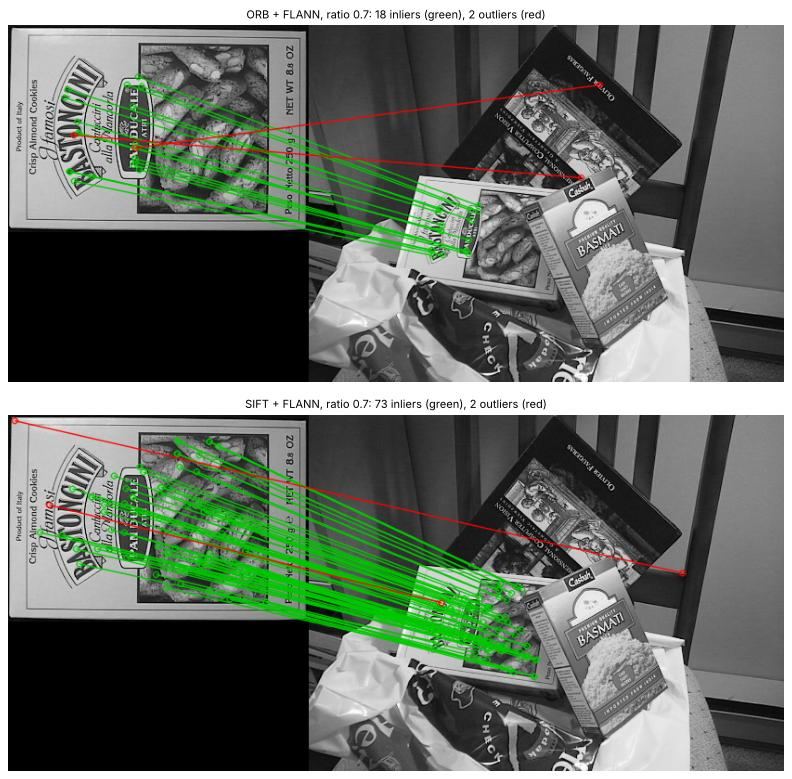

In [5]:
logo_c, scene_c = imread_checked(os.path.join(DATA, "box.png")), imread_checked(os.path.join(DATA, "box_in_scene.png"))
panels, titles = [], []
for method in ["orb", "sift"]:
    det = make_detector(method)
    t = time.perf_counter()
    ka, da = det.detectAndCompute(logo, None)
    kb, db = det.detectAndCompute(scene, None)
    t_det = time.perf_counter() - t
    t = time.perf_counter()
    good_m = ratio_matches(da, db, method, 0.7)
    t_match = time.perf_counter() - t
    H, inl, n_in = ransac_homography(ka, kb, good_m)
    print(f"{method.upper():4s}: keypoints {len(ka)}/{len(kb)}, good {len(good_m)}, inliers {n_in} "
          f"({100 * n_in / max(1, len(good_m)):.0f}%), detect+describe {1000 * t_det:.0f} ms, match {1000 * t_match:.1f} ms")
    vis = cv2.drawMatches(logo_c, ka, scene_c, kb, [m for m, i in zip(good_m, inl) if i], None,
                          matchColor=(0, 200, 0), flags=2)
    vis = cv2.drawMatches(logo_c, ka, scene_c, kb, [m for m, i in zip(good_m, inl) if not i], vis,
                          matchColor=(0, 0, 255), flags=2 | cv2.DrawMatchesFlags_DRAW_OVER_OUTIMG)
    panels.append(vis); titles.append(f"{method.upper()} + FLANN, ratio 0.7: {n_in} inliers (green), {len(good_m) - n_in} outliers (red)")
show(panels, titles, cols=1, size=10)

### 5a · How the ratio threshold changes the matches (0.5 … 0.95)

For each threshold we count the good matches and how many survive RANSAC. The **inlier %** tells us how clean the set is.


ORB   ratio   good  inliers  inlier%
        0.50      6        6     100%
        0.60     13       13     100%
        0.70     22       21      95%
        0.75     32       25      78%
        0.80     42       29      69%
        0.90    126       43      34%
        0.95    247       47      19%

SIFT   ratio   good  inliers  inlier%
        0.50     43       43     100%
        0.60     61       60      98%
        0.70     75       73      97%
        0.75     80       74      92%


        0.80     96       78      81%
        0.90    191       85      45%
        0.95    320       89      28%


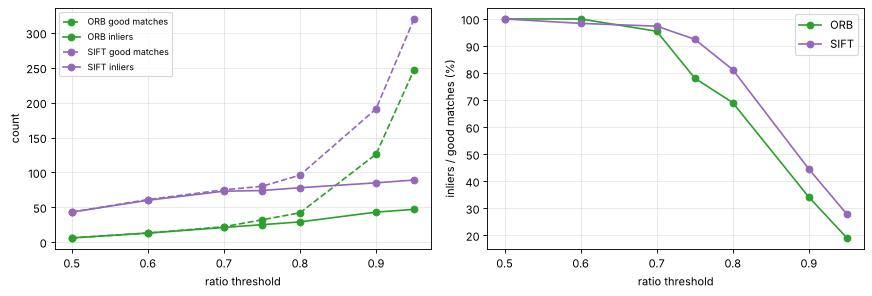

In [6]:
ratios = [0.5, 0.6, 0.7, 0.75, 0.8, 0.9, 0.95]
sweep = {}
for method in ["orb", "sift"]:
    det = make_detector(method)
    ka, da = det.detectAndCompute(logo, None); kb, db = det.detectAndCompute(scene, None)
    print(f"\n{method.upper()}   ratio   good  inliers  inlier%")
    for r in ratios:
        g = ratio_matches(da, db, method, r)
        _, _, n_in = ransac_homography(ka, kb, g)
        sweep[(method, r)] = (len(g), n_in)
        print(f"        {r:4.2f}  {len(g):5d}  {n_in:7d}  {100 * n_in / max(1, len(g)):6.0f}%")

fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
for method, c in [("orb", "tab:green"), ("sift", "tab:purple")]:
    g = [sweep[(method, r)][0] for r in ratios]; i = [sweep[(method, r)][1] for r in ratios]
    ax[0].plot(ratios, g, "--o", color=c, label=f"{method.upper()} good matches")
    ax[0].plot(ratios, i, "-o", color=c, label=f"{method.upper()} inliers")
    ax[1].plot(ratios, [100 * b / max(1, a) for a, b in zip(g, i)], "-o", color=c, label=method.upper())
ax[0].set_xlabel("ratio threshold"); ax[0].set_ylabel("count"); ax[0].legend(fontsize=8); ax[0].grid(alpha=.3)
ax[1].set_xlabel("ratio threshold"); ax[1].set_ylabel("inliers / good matches (%)"); ax[1].legend(); ax[1].grid(alpha=.3)
plt.tight_layout(); plt.show()

**Reading the sweep:**
- At **0.5–0.6** almost every surviving match is correct (98–100 % inliers), but there are very few (ORB: 6–13).
- At **0.7** (course value) ORB keeps 22 matches with 95 % inliers; SIFT keeps 75 with 97 %.
- From **0.8** upwards the number of "good" matches shoots up (ORB 42 → 126 → 247) but the number of *inliers* barely grows (29 → 43 → 47): **the extra matches are mostly wrong**. At 0.95 only 19 % (ORB) and 28 % (SIFT) of the matches are correct.
- So the ratio test is a trade-off: low ratio = few, clean matches; high ratio = many, dirty matches. **0.7–0.8 is the sweet spot**, which is why Lowe suggested 0.8 and the course uses 0.7.
- SIFT gives **3–4× more inliers** than ORB on this pair at every ratio. The box in the scene is smaller and rotated, and SIFT handles scale change better (see Day 8).
- **FLANN is randomised.** The course cell in §3 found 20 good ORB matches at 0.7, and the sweep found 22 with the same images and settings, because each FLANN-LSH index is built with random hash functions. Re-running a cell can change the counts slightly; the conclusions don't change.

### 5b · Brute force vs FLANN: is FLANN really faster?

FLANN's advantage appears with **many** descriptors. We match SIFT descriptors of two 800×640 graffiti photos (`graf1.png`, `graf3.png`, a strong viewpoint change) with both matchers. We also check how many of FLANN's nearest neighbours are the true nearest neighbour (its *approximation* error).

In [7]:
g1 = imread_checked(os.path.join(DATA, "graf1.png"), cv2.IMREAD_GRAYSCALE)
g3 = imread_checked(os.path.join(DATA, "graf3.png"), cv2.IMREAD_GRAYSCALE)
sift = cv2.SIFT_create()
k1, d1 = sift.detectAndCompute(g1, None); k3, d3 = sift.detectAndCompute(g3, None)
print(f"SIFT descriptors: {len(d1)} x {len(d3)}  -> brute force computes {len(d1) * len(d3) / 1e6:.1f} million distances")

def time_it(fn, reps=3):
    ts = []
    for _ in range(reps):
        t = time.perf_counter(); out = fn(); ts.append(time.perf_counter() - t)
    return out, 1000 * min(ts)

bf_knn, t_bf = time_it(lambda: cv2.BFMatcher(cv2.NORM_L2).knnMatch(d1, d3, k=2))
fl_knn, t_fl = time_it(lambda: make_flann("sift").knnMatch(d1, d3, k=2))
same = np.mean([a[0].trainIdx == b[0].trainIdx for a, b in zip(bf_knn, fl_knn)])
print(f"BFMatcher (exact):     {t_bf:6.0f} ms")
print(f"FLANN KD-tree (5 trees, checks=50): {t_fl:6.0f} ms  (includes building the index)")
print(f"FLANN found the same nearest neighbour as brute force for {100 * same:.0f}% of descriptors")
for name, knn in [("BF", bf_knn), ("FLANN", fl_knn)]:
    gm = [p[0] for p in knn if len(p) == 2 and p[0].distance < 0.7 * p[1].distance]
    _, _, n_in = ransac_homography(k1, k3, gm)
    print(f"{name:5s}: {len(gm)} good matches after ratio test, {n_in} RANSAC inliers")

kb_o, db_o = cv2.ORB_create(nfeatures=5000).detectAndCompute(g1, None)
kc_o, dc_o = cv2.ORB_create(nfeatures=5000).detectAndCompute(g3, None)
_, t_bf_o = time_it(lambda: cv2.BFMatcher(cv2.NORM_HAMMING).knnMatch(db_o, dc_o, k=2))
_, t_fl_o = time_it(lambda: make_flann("orb").knnMatch(db_o, dc_o, k=2))
print(f"\nORB {len(db_o)} x {len(dc_o)}:  BF Hamming {t_bf_o:.0f} ms | FLANN LSH {t_fl_o:.0f} ms")

SIFT descriptors: 2665 x 3498  -> brute force computes 9.3 million distances


BFMatcher (exact):        173 ms
FLANN KD-tree (5 trees, checks=50):     61 ms  (includes building the index)
FLANN found the same nearest neighbour as brute force for 82% of descriptors
BF   : 378 good matches after ratio test, 344 RANSAC inliers
FLANN: 395 good matches after ratio test, 357 RANSAC inliers



ORB 5000 x 5000:  BF Hamming 192 ms | FLANN LSH 50 ms


**Reading the timings:**
- With ~2,700 × ~3,500 SIFT descriptors, FLANN (KD-tree) was several times faster than brute force (see the printed times; they vary from run to run with machine load). For ORB with 5000 × 5000 descriptors, LSH was also several times faster than brute-force Hamming.
- FLANN is **approximate**: only 82 % of its nearest neighbours were the true nearest neighbour. After the ratio test and RANSAC this hardly matters (395 vs 378 good matches, 357 vs 344 inliers). The neighbours it gets "wrong" are mostly ambiguous descriptors that the ratio test would reject anyway.
- For a small logo (a few hundred descriptors) matching takes only a few milliseconds either way (§5: ORB 1.4 ms). FLANN pays off for **large** descriptor sets or databases of many images. Detection and description usually cost more than matching: SIFT took about 200 ms to describe the box and the scene, ORB about 7 ms.

### 5c · What if the logo is NOT in the scene?

A detector that always "finds" something is useless. We match the box against five scenes that do **not** contain it and look at the numbers the course code uses to decide (`len(good) > 10`).

In [8]:
negatives = ["messi5.jpg", "building.jpg", "home.jpg", "left01.jpg", "graf1.png"]
neg_rows = []
print(f"{'scene':13s} {'method':6s} {'ratio':>5s} {'good':>5s} {'inliers':>7s} {'inlier%':>7s}  course rule (good > 10)")
for name in negatives:
    sc = imread_checked(os.path.join(DATA, name), cv2.IMREAD_GRAYSCALE)
    for method in ["orb", "sift"]:
        det = make_detector(method)
        ka, da = det.detectAndCompute(logo, None); kb, db = det.detectAndCompute(sc, None)
        for r in [0.7, 0.8, 0.9]:
            g = ratio_matches(da, db, method, r)
            _, _, n_in = ransac_homography(ka, kb, g)
            neg_rows.append((name, method, r, len(g), n_in))
            print(f"{name:13s} {method:6s} {r:5.1f} {len(g):5d} {n_in:7d} {100 * n_in / max(1, len(g)):6.0f}%  "
                  f"{'FALSE DETECTION' if len(g) > 10 else 'not found (correct)'}")

scene         method ratio  good inliers inlier%  course rule (good > 10)
messi5.jpg    orb      0.7     0       0      0%  not found (correct)
messi5.jpg    orb      0.8    17       5     29%  FALSE DETECTION
messi5.jpg    orb      0.9   116      11      9%  FALSE DETECTION
messi5.jpg    sift     0.7     3       0      0%  not found (correct)
messi5.jpg    sift     0.8    22       8     36%  FALSE DETECTION


messi5.jpg    sift     0.9   123      11      9%  FALSE DETECTION
building.jpg  orb      0.7     6       0      0%  not found (correct)
building.jpg  orb      0.8    12       4     33%  FALSE DETECTION
building.jpg  orb      0.9    93       6      6%  FALSE DETECTION


building.jpg  sift     0.7     1       0      0%  not found (correct)
building.jpg  sift     0.8    11       4     36%  FALSE DETECTION
building.jpg  sift     0.9   120       7      6%  FALSE DETECTION
home.jpg      orb      0.7     4       4    100%  not found (correct)
home.jpg      orb      0.8    18       5     28%  FALSE DETECTION
home.jpg      orb      0.9   115       9      8%  FALSE DETECTION


home.jpg      sift     0.7     1       0      0%  not found (correct)
home.jpg      sift     0.8    15       6     40%  FALSE DETECTION
home.jpg      sift     0.9    98      10     10%  FALSE DETECTION
left01.jpg    orb      0.7     3       0      0%  not found (correct)
left01.jpg    orb      0.8    17       5     29%  FALSE DETECTION
left01.jpg    orb      0.9    60       5      8%  FALSE DETECTION


left01.jpg    sift     0.7     2       0      0%  not found (correct)
left01.jpg    sift     0.8    12       4     33%  FALSE DETECTION
left01.jpg    sift     0.9    91       7      8%  FALSE DETECTION
graf1.png     orb      0.7     1       0      0%  not found (correct)
graf1.png     orb      0.8    25      10     40%  FALSE DETECTION
graf1.png     orb      0.9   120       9      8%  FALSE DETECTION


graf1.png     sift     0.7     2       0      0%  not found (correct)
graf1.png     sift     0.8    14       5     36%  FALSE DETECTION
graf1.png     sift     0.9   117       9      8%  FALSE DETECTION


**This is important.** At the course's ratio of **0.7**, every negative scene gives at most 6 good matches, so `len(good) > 10` correctly says "not found". But the rule only works because the ratio is strict. At **0.8**, every one of the 10 negative tests (5 scenes × ORB/SIFT) has 11–25 "good" matches, and the course rule **falsely reports the logo in all of them**; at 0.9 there are 60–123.

What *does* separate positives from negatives is **geometry**: in the negative scenes at most 11 matches agree with any single homography (RANSAC inliers), while the real box gives 18–21 (ORB) and 73 (SIFT) inliers in `box_in_scene.png`. Note `home.jpg`, ORB, 0.7: 4 good matches, 4 inliers, "100 %". **Any 4 matches fit a homography perfectly**, so an inlier ratio is meaningless when there are only a handful of matches; you need a minimum inlier *count* as well.

## 6 · Mini project: logo detector

### 6a · The course's mini-project cell, explained
This is the course code (it continues from the `good` matches of §3), with comments. It works on our real logo/scene pair.

20 good matches, 20 RANSAC inliers


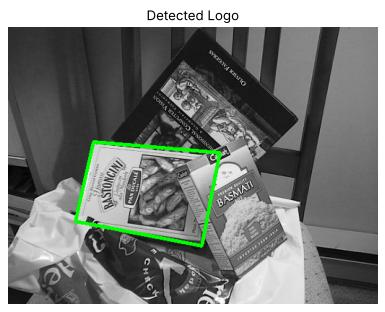

In [9]:
# Extract matched keypoints
if len(good) > 10:                                     # need enough matches to trust a homography
    src_pts = np.float32([ kp1[m.queryIdx].pt for m in good ]).reshape(-1,1,2)   # points in the logo
    dst_pts = np.float32([ kp2[m.trainIdx].pt for m in good ]).reshape(-1,1,2)   # where they are in the scene

    # Find homography: logo plane -> scene, RANSAC with 5-pixel reprojection threshold
    M, mask = cv2.findHomography(src_pts, dst_pts, cv2.RANSAC, 5.0)
    h, w = logo.shape
    pts = np.float32([[0,0],[0,h-1],[w-1,h-1],[w-1,0]]).reshape(-1,1,2)   # the logo's 4 corners
    dst = cv2.perspectiveTransform(pts, M)                                 # ...projected into the scene

    scene_color = cv2.cvtColor(scene, cv2.COLOR_GRAY2BGR)                  # colour copy so we can draw in green
    cv2.polylines(scene_color, [np.int32(dst)], True, (0,255,0), 3)        # closed polygon, green, 3 px

    print(f"{len(good)} good matches, {int(mask.sum())} RANSAC inliers")
    plt.figure(figsize=(6, 4.5))
    plt.imshow(cv2.cvtColor(scene_color, cv2.COLOR_BGR2RGB))             # course: plt.imshow(scene_color)
    plt.title("Detected Logo")
    plt.axis('off')
    plt.show()
else:
    print("Not enough matches found - try another image or adjust parameters.")

**The RANSAC reprojection threshold `5.0`:** after fitting H, a match counts as an inlier if the logo point, projected with H, lands within 5 pixels of its matched scene point. Smaller → stricter (fewer inliers, more precise H); larger → tolerates noisy keypoints but also lets some wrong matches in. 3–5 px is typical.

**What the course cell does not check:** whether `M` is `None` (it is when RANSAC fails), how many matches are *inliers* (it only counts ratio-test matches), and whether the box is a sensible shape (a twisted "bow-tie" polygon means H is nonsense). The course notebook's own saved output shows this failure: matching `left.jpg` against `right.jpg` drew a green line running off the image, because the whole "logo" image is not a flat object.

### 6b · An improved, reusable detector
Same pipeline (detect → FLANN → ratio test → RANSAC homography → project corners), plus three sanity checks that decide **found / not found**:
1. at least `min_inliers` (12) RANSAC inliers;
2. at least 25 % of the good matches are inliers;
3. the projected box is **convex** and not tiny (no twisted or collapsed polygons).

True | 29 inliers / 32 good


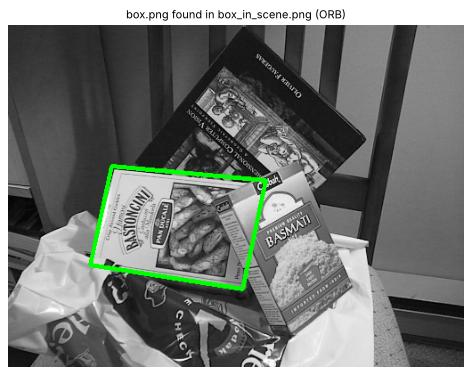

In [10]:
def detect_logo(logo_gray, scene_gray, method="orb", ratio=0.7, nfeatures=1000, min_inliers=12, min_inlier_ratio=0.25):
    det = make_detector(method, nfeatures)
    ka, da = det.detectAndCompute(logo_gray, None)
    kb, db = det.detectAndCompute(scene_gray, None)
    good = ratio_matches(da, db, method, ratio)
    H, inl, n_in = ransac_homography(ka, kb, good)
    res = dict(method=method, good=len(good), inliers=n_in, H=H, found=False, box=None, reason="")
    if H is None:
        res["reason"] = f"only {len(good)} good matches"
        return res
    h, w = logo_gray.shape[:2]
    box = cv2.perspectiveTransform(np.float32([[0, 0], [w - 1, 0], [w - 1, h - 1], [0, h - 1]]).reshape(-1, 1, 2), H)
    res["box"] = box.reshape(-1, 2)
    area = cv2.contourArea(box)
    if n_in < min_inliers:
        res["reason"] = f"{n_in} inliers < {min_inliers}"
    elif n_in / len(good) < min_inlier_ratio:
        res["reason"] = f"inlier ratio {n_in / len(good):.0%} too low"
    elif not cv2.isContourConvex(np.int32(box)) or area < 0.002 * scene_gray.size:
        res["reason"] = "box not a sensible shape"
    else:
        res["found"], res["reason"] = True, f"{n_in} inliers / {len(good)} good"
    return res

def draw_result(scene_bgr, res, gt=None):
    vis = scene_bgr.copy()
    if gt is not None:
        cv2.polylines(vis, [np.int32(gt)], True, (255, 0, 0), 2)                     # ground truth in blue
    if res["box"] is not None:
        cv2.polylines(vis, [np.int32(res["box"])], True, (0, 255, 0) if res["found"] else (0, 0, 255), 3)
    return vis

res = detect_logo(logo, scene, "orb")
print(res["found"], "|", res["reason"])
show(draw_result(scene_c, res), "box.png found in box_in_scene.png (ORB)", size=6)

### 6c · Measured robustness: logo pasted into a scene with a KNOWN transformation

For `box_in_scene.png` we don't know the exact true position, so we can't measure accuracy. So we make our own test scenes: we warp the logo with a known homography (rotation, zoom, perspective tilt) and paste it into a cluttered photo (`messi5.jpg`, enlarged to 800×500). Because we know where the corners *should* be, we can measure the **corner error** in pixels. Blue = ground truth, green = detected.

case                       | ORB: found  inliers  corner err  | SIFT: found  inliers  corner err


identity                   |        True      388       0.7 px       |        True      417       0.1 px      


rotate 30                  |        True      378       0.7 px       |        True      414       0.2 px      


rotate 90                  |        True      393       1.1 px       |        True      409       0.5 px      
rotate 180                 |        True      398       1.4 px       |        True      412       0.7 px      


zoom 0.5                   |        True       57       1.2 px       |        True      111       0.4 px      
zoom 0.35                  |       False        4      93.5 px       |        True       67       0.8 px      


zoom 1.5                   |        True      269       2.1 px       |        True      399       0.2 px      
rot 20 + zoom 0.7 + tilt   |        True       37       3.9 px       |        True       77       0.5 px      


strong tilt                |        True       34       8.7 px       |        True       61       0.6 px      


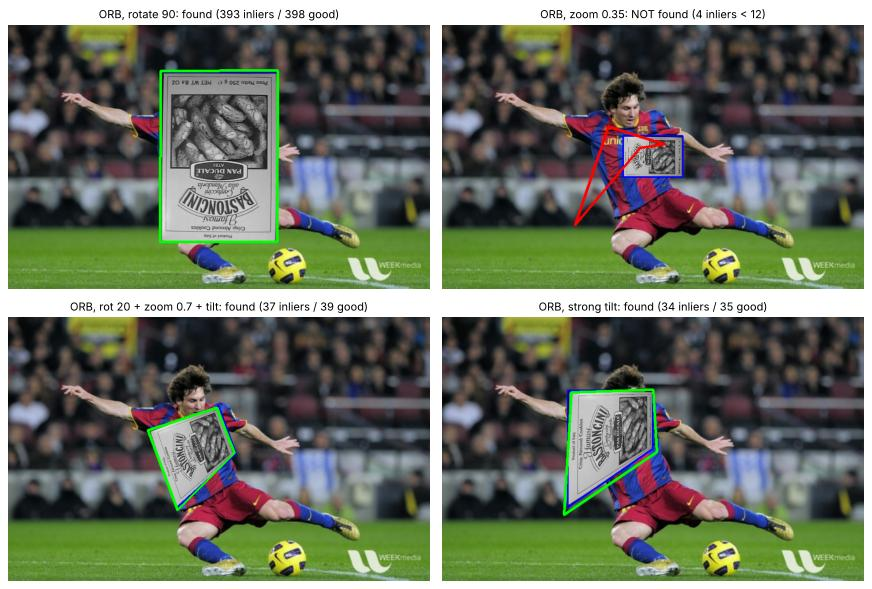

In [11]:
bg = cv2.resize(imread_checked(os.path.join(DATA, "messi5.jpg")), (800, 500))

def make_test_scene(logo_bgr, angle=0, scale=1.0, tilt=0.0, centre=(400, 250)):
    """Warp the logo (rotate/scale about its centre, optional perspective tilt) and paste it into bg."""
    h, w = logo_bgr.shape[:2]
    R = np.vstack([cv2.getRotationMatrix2D((w / 2, h / 2), angle, scale), [0, 0, 1]])
    T = np.array([[1, 0, centre[0] - w / 2], [0, 1, centre[1] - h / 2], [0, 0, 1]], dtype=float)
    P = np.array([[1, 0, 0], [0, 1, 0], [tilt / w, 0, 1]], dtype=float)           # perspective: right side further away
    H = T @ R @ P
    warped = cv2.warpPerspective(logo_bgr, H, (bg.shape[1], bg.shape[0]))
    m = cv2.warpPerspective(np.full(logo_bgr.shape[:2], 255, np.uint8), H, (bg.shape[1], bg.shape[0]))
    sc = bg.copy(); sc[m > 0] = warped[m > 0]
    gt = cv2.perspectiveTransform(np.float32([[0, 0], [w - 1, 0], [w - 1, h - 1], [0, h - 1]]).reshape(-1, 1, 2), H)
    return sc, gt.reshape(-1, 2)

cases = [("identity", 0, 1.0, 0.0), ("rotate 30", 30, 1.0, 0.0), ("rotate 90", 90, 1.0, 0.0), ("rotate 180", 180, 1.0, 0.0),
         ("zoom 0.5", 0, 0.5, 0.0), ("zoom 0.35", 0, 0.35, 0.0), ("zoom 1.5", 0, 1.5, 0.0),
         ("rot 20 + zoom 0.7 + tilt", 20, 0.7, 0.6), ("strong tilt", 0, 1.0, 1.0)]
print(f"{'case':26s} | {'ORB: found  inliers  corner err':32s} | {'SIFT: found  inliers  corner err'}")
panels, titles = [], []
for name, a, s, t in cases:
    sc, gt = make_test_scene(logo_c, a, s, t)
    sg = cv2.cvtColor(sc, cv2.COLOR_BGR2GRAY)
    line = f"{name:26s}"
    for method in ["orb", "sift"]:
        r = detect_logo(logo, sg, method)
        err = np.linalg.norm(r["box"] - gt, axis=1).mean() if r["box"] is not None else float("nan")
        line += f" | {str(r['found']):>11s} {r['inliers']:8d} {err:9.1f} px      "
        if method == "orb" and name in ("rotate 90", "zoom 0.35", "rot 20 + zoom 0.7 + tilt", "strong tilt"):
            panels.append(draw_result(sc, r, gt)); titles.append(f"ORB, {name}: {'found' if r['found'] else 'NOT found'} ({r['reason']})")
    print(line)
show(panels, titles, cols=2, size=5.5)

**Reading the table:**
- **Rotation is no problem** for either method (0–180°): both found the box every time; ORB corner error 0.7–1.4 px, SIFT 0.1–0.7 px.
- **Zoom:** at 0.5× both still work (ORB with 57 inliers instead of ~390). At **0.35×** (the box is only about 110 px wide) ORB finds just 4 inliers; RANSAC returns a nonsense box (93.5 px corner error, the red triangle above) and our sanity checks **correctly reject it**. SIFT still finds it (67 inliers, 0.8 px error). This is the "ORB is weaker on scale" claim, measured.
- **Perspective tilt:** both found it; ORB's corners are less precise (3.9 px and 8.7 px error) than SIFT's (0.5–0.6 px). SIFT's sub-pixel keypoint localisation and richer descriptor give more, and more precise, inliers.
- Overall: ORB found the logo in 8 of 9 cases, SIFT in 9 of 9. SIFT's corner errors stayed at or below 0.8 px; ORB's ranged from 0.7 to 8.7 px.

### 6d · A real logo: the OpenCV logo pasted into a scene

Real logos are often **flat colour shapes**: few textures, many smooth edges, repeated elements (the OpenCV logo has three similar rings). That is a harder case for feature matching than a richly printed cereal box.

logo size (318, 240) | ORB keypoints 255 | SIFT keypoints 97
rotate 20, zoom 0.8  ORB : found=True  34 inliers / 44 good         corner error 9.2 px
rotate 20, zoom 0.8  SIFT: found=True  48 inliers / 55 good         corner error 0.5 px
zoom 0.6             ORB : found=True  18 inliers / 28 good         corner error 2.5 px


zoom 0.6             SIFT: found=True  38 inliers / 43 good         corner error 0.9 px
zoom 0.4 + tilt      ORB : found=False only 0 good matches          corner error nan px
zoom 0.4 + tilt      SIFT: found=False only 3 good matches          corner error nan px


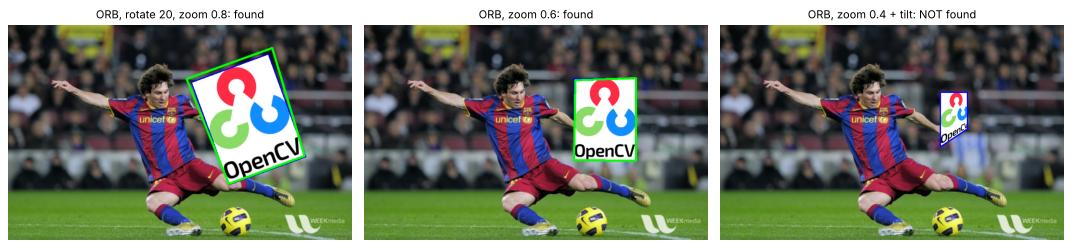

In [12]:
L = imread_checked(os.path.join(DATA, "opencv-logo.png"), cv2.IMREAD_UNCHANGED)     # 4 channels: B, G, R, alpha
alpha = L[..., 3:4] / 255.0
logo2 = (L[..., :3] * alpha + 255 * (1 - alpha)).astype(np.uint8)                  # put it on a white background
logo2 = cv2.resize(logo2, None, fx=0.4, fy=0.4, interpolation=cv2.INTER_AREA)
logo2_g = cv2.cvtColor(logo2, cv2.COLOR_BGR2GRAY)
print("logo size", logo2.shape[:2], "| ORB keypoints", len(cv2.ORB_create(1000).detect(logo2_g, None)),
      "| SIFT keypoints", len(cv2.SIFT_create().detect(logo2_g, None)))

panels, titles = [], []
for name, a, s, t in [("rotate 20, zoom 0.8", 20, 0.8, 0.0), ("zoom 0.6", 0, 0.6, 0.0), ("zoom 0.4 + tilt", 0, 0.4, 0.5)]:
    sc, gt = make_test_scene(logo2, a, s, t, centre=(560, 220))
    sg = cv2.cvtColor(sc, cv2.COLOR_BGR2GRAY)
    for method in ["orb", "sift"]:
        r = detect_logo(logo2_g, sg, method)
        err = np.linalg.norm(r["box"] - gt, axis=1).mean() if r["box"] is not None else float("nan")
        print(f"{name:20s} {method.upper():4s}: found={r['found']!s:5s} {r['reason']:28s} corner error {err:.1f} px")
        if method == "orb":
            panels.append(draw_result(sc, r, gt)); titles.append(f"ORB, {name}: {'found' if r['found'] else 'NOT found'}")
show(panels, titles, cols=3, size=4.5)

**Reading the result:**
- The flat OpenCV logo gives only **97 SIFT keypoints** (flat colour has few blob-like structures). ORB finds 255, mostly on the text "OpenCV" and on the ring edges.
- At 0.8× and 0.6× both methods find it. ORB's box is less precise (9.2 px and 2.5 px corner error, against SIFT's 0.5 and 0.9 px).
- At **0.4× with tilt** (logo ≈ 95 px wide) **both fail** (0 and 3 good matches) and the detector honestly says "not found". Small, flat, low-texture logos are the weak spot of keypoint matching. Remedies: a larger template, matching at several template scales, or a trained detector (CNN, Week 3).

### 6e · The detector on scenes without the logo

In [13]:
print("ratio 0.7 (default) and the looser 0.9:")
for name in negatives:
    sg = imread_checked(os.path.join(DATA, name), cv2.IMREAD_GRAYSCALE)
    out = []
    for method in ["orb", "sift"]:
        for r in [0.7, 0.9]:
            res = detect_logo(logo, sg, method, ratio=r)
            out.append(f"{method.upper()}@{r}: {'FOUND' if res['found'] else 'no'} ({res['reason']})")
    print(f"{name:13s} " + " | ".join(out))

ratio 0.7 (default) and the looser 0.9:


messi5.jpg    ORB@0.7: no (only 0 good matches) | ORB@0.9: no (10 inliers < 12) | SIFT@0.7: no (only 3 good matches) | SIFT@0.9: no (inlier ratio 12% too low)


building.jpg  ORB@0.7: no (only 1 good matches) | ORB@0.9: no (9 inliers < 12) | SIFT@0.7: no (only 1 good matches) | SIFT@0.9: no (6 inliers < 12)


home.jpg      ORB@0.7: no (only 1 good matches) | ORB@0.9: no (11 inliers < 12) | SIFT@0.7: no (only 2 good matches) | SIFT@0.9: no (0 inliers < 12)


left01.jpg    ORB@0.7: no (4 inliers < 12) | ORB@0.9: no (8 inliers < 12) | SIFT@0.7: no (only 2 good matches) | SIFT@0.9: no (6 inliers < 12)


graf1.png     ORB@0.7: no (4 inliers < 12) | ORB@0.9: no (9 inliers < 12) | SIFT@0.7: no (only 1 good matches) | SIFT@0.9: no (9 inliers < 12)


With the improved decision rule (inliers ≥ 12, inlier ratio ≥ 25 %, convex box), there were **0 false detections in 20 negative tests**, even at the loose ratio 0.9 where the course rule failed every time. **Honest caveat:** at ratio 0.9 the margin is thin. ORB on `home.jpg` reached 11 inliers, just below our threshold of 12. With ratio 0.7 the negatives never exceeded 4 inliers, while true detections had ≥ 18. So: keep the ratio at 0.7–0.8 **and** decide on inliers.

## 7 · 🔧 What we changed from the course notebook, and why

| # | Course code | Problem (verified) | What we did |
|---|---|---|---|
| 1 | `cv2.imread('left.jpg')`, `'right.jpg'` (and `logo.jpg`/`scene.jpg` in the exercise) | Files not provided → `None` → crash in `detectAndCompute`. Also, `left/right` are two views of a scene, **not a logo and a scene**, so the "detected logo" box in the course's saved output is meaningless (a line running off the image) | Real logo/scene pair `box.png` / `box_in_scene.png`, the OpenCV logo, and synthetic scenes with known ground truth |
| 2 | `for m,n in matches:` | **Crashes** with `ValueError: not enough values to unpack` when FLANN-LSH returns < 2 neighbours (reproduced in §4 with a small scene) | `[p[0] for p in matches if len(p) == 2 and ...]` |
| 3 | `plt.imshow(img_matches)`, `plt.imshow(scene_color)` | `drawMatches`/`cvtColor(GRAY2BGR)` give **BGR** images; matplotlib expects RGB. Invisible here (grey photo, random/green lines) but wrong colours with colour inputs | `cv2.cvtColor(..., cv2.COLOR_BGR2RGB)` before `plt.imshow` |
| 4 | Decision rule `len(good) > 10` | Counts ratio-test matches, not geometric agreement. At ratio 0.8 or 0.9 it reports the logo in every negative scene we tried (§5c) | Decide on RANSAC **inliers**, inlier ratio and a convex box |
| 5 | `M` from `findHomography` used without checking | It is `None` when RANSAC fails → `perspectiveTransform` crashes | Check `H is None` |
| 6 | No check for `des is None` | Images without keypoints crash `knnMatch` | Guard in `ratio_matches` |
| 7 | Exercise "observe how many matches… how accurate" | No measurement | Inlier counts, ratio sweep, ORB vs SIFT, BF vs FLANN timing, ground-truth corner errors, negatives |

## 8 · Results, honestly


- The course pipeline (ORB → FLANN-LSH → ratio 0.7 → RANSAC homography → polygon) **works** once it is given a real logo and scene: it located the box in `box_in_scene.png` with 20 good matches, all RANSAC inliers.
- It has a **real crash** (`for m, n in matches` with FLANN-LSH, reproduced) and a **weak decision rule** (`len(good) > 10`, which falsely detects the logo in every negative scene once the ratio is relaxed to 0.8).
- **SIFT beat ORB on accuracy** in every test (more inliers, corner errors ≤ 0.9 px against ORB's up to 9.2 px, and it survived 0.35× zoom); **ORB was far faster** to detect and describe (about 7 ms against about 200 ms for SIFT in §5). For real-time use ORB is still the practical choice.
- Lowering the ratio threshold trades quantity for quality; 0.7–0.8 was the sweet spot on our data.
- FLANN's speed advantage only matters for thousands of descriptors; its approximation did not hurt the final result.
- Limitations: our synthetic tests paste a perfectly flat, sharp logo with no blur, lighting change or occlusion, so real photos will be harder. Timings depend on the machine.

## 9 · Common errors and how to fix them

| Error / symptom | Cause | Fix |
|---|---|---|
| `ValueError: not enough values to unpack (expected 2, got 1)` in `for m, n in matches` | FLANN-LSH returned < 2 neighbours | `if len(p) == 2` guard (§4) |
| `error: (-215) ... in function 'knnMatch'` / "unsupported format" | Descriptors are `None`, or type does not fit the index: SIFT (float32) needs KD-tree / `NORM_L2`, ORB (uint8) needs LSH / `NORM_HAMMING` | Check `des is None`; pick the matching index/norm; never `astype` ORB descriptors to float for a KD-tree |
| `crossCheck=True` + `knnMatch(k=2)` gives empty/odd results | Cross-check and ratio test are alternative filters | Use `BFMatcher(norm)` (crossCheck False) for the ratio test |
| Very few good matches | Logo too small in the scene, blurry, low texture, ratio too strict, ORB's 500-point cap | Use more features (`ORB_create(2000)`), SIFT, ratio 0.75–0.8, larger logo image |
| Box drawn as a twisted "bow tie" or a huge shape | Homography fitted to wrong matches (logo not present or too few inliers) | Require ≥ 10–15 inliers, inlier ratio, convex box (`cv2.isContourConvex`) |
| `findHomography` returns `None` | < 4 matches or degenerate points | Check before using |
| Box slightly off for non-flat objects | A homography only describes **flat** objects | Use a planar logo; for 3-D objects use pose estimation (`solvePnP`) |
| Colours swapped in plots | BGR vs RGB | `cv2.cvtColor(img, cv2.COLOR_BGR2RGB)` |

## 10 · Try this yourself

1. Photograph a book cover or a cereal box (the "logo") and then a messy desk with it lying at an angle (the "scene"). Run `detect_logo` with ORB and SIFT. At which angle/distance does each one fail?
2. Change the RANSAC threshold (1, 3, 5, 10 px) in `ransac_homography` and watch the inlier count and the corner error in §6c.
3. Replace RANSAC with `cv2.USAC_MAGSAC` (a modern robust estimator in OpenCV ≥ 4.5): `cv2.findHomography(src, dst, cv2.USAC_MAGSAC, 5.0)`. Is it more accurate?
4. Make the logo detector find **two copies** of the logo: after the first detection, remove its inlier matches and run RANSAC again on the rest.
5. Change `table_number`, `key_size`, `multi_probe_level` and `checks` for LSH. How do the number of neighbours returned and the match quality change?
6. Use `cv2.BFMatcher(cv2.NORM_HAMMING, crossCheck=True)` instead of the ratio test. Which gives a cleaner match set on `box_in_scene.png`?

## 11 · Viva questions (with short model answers)

1. **What is a feature descriptor?** A vector that summarises the image patch around a keypoint (gradients for SIFT, binary intensity comparisons for ORB) so keypoints in different images can be compared.
2. **SIFT vs ORB descriptor?** SIFT: 128 floats, L2 distance, very distinctive, slow. ORB: 256 bits (32 bytes), Hamming distance (XOR + popcount), very fast, a little less distinctive.
3. **Why Hamming distance for ORB?** The descriptor is a bit string; the natural dissimilarity is the number of differing bits, computed with one XOR and a bit count.
4. **Brute force vs FLANN?** BF compares all pairs (exact, O(N·M)); FLANN builds an index (KD-trees / LSH) and finds *approximate* nearest neighbours much faster for large sets. For a few hundred descriptors BF is just as fast.
5. **Why does ORB need an LSH index in FLANN?** KD-trees work on real-valued vectors with Euclidean distance; binary strings with Hamming distance need hashing (LSH: `algorithm=6`, `table_number`, `key_size`, `multi_probe_level`).
6. **Explain Lowe's ratio test.** For each descriptor take the two nearest neighbours; accept the best only if `d1 < ratio·d2` (0.7–0.8). Ambiguous matches (two similar candidates, e.g. repetitive texture) are rejected; Lowe showed this removes ~90 % of false matches while losing < 5 % of correct ones.
7. **Effect of the ratio value?** Lower (0.5) → few but very reliable matches; higher (0.9) → many matches with many outliers. Our sweep: the inlier percentage dropped as the ratio rose (see §5a).
8. **Why `k=2` in `knnMatch`?** The ratio test needs the best and the second-best neighbour.
9. **What is a homography and why can it locate a logo?** A 3×3 projective transform between two planes; a flat logo seen from any viewpoint maps to the scene by a homography, so projecting the logo's corners gives its outline.
10. **Minimum matches for a homography? Why use more?** 4 (8 unknowns, 2 equations per point). More, plus RANSAC, to average out noise and reject wrong matches.
11. **What does RANSAC do and what is the threshold 5.0?** It repeatedly fits H to 4 random matches and keeps the model with most inliers (matches whose reprojection error is < 5 px).
12. **How do you know the logo is NOT in the scene?** Too few RANSAC inliers, a low inlier ratio, or an implausible (non-convex, tiny) box. Counting ratio-test matches alone is not enough: at ratio 0.9 every negative scene we tried passed the course's `len(good) > 10` rule.
13. **What bug can `for m, n in matches` cause?** With FLANN-LSH some queries get fewer than 2 neighbours → `ValueError`. Guard with `len(p) == 2`.
14. **Which is more robust to scale change, ORB or SIFT? Evidence?** SIFT: in our ground-truth test it still found the box at zoom 0.35 while ORB did not (see §6c).
15. **Real-world uses?** Brand monitoring (logos in broadcast/social media), augmented reality (marker-less tracking of a magazine page), visual search, document alignment, robot object recognition.